# Module 2: Random Walks and Time Series, Tested on Real Data

*By Héctor Ornelas*

In Module 1 each return was a single random variable. In this module the returns get a time index,
and the questions are about how they behave one after the other: does risk grow in a predictable way,
does the market remember what it did before, and do some series go back to an average. The course
answers these questions with simulated random walks and with AR and MA models. Here I take the same
eight topics, in the same order, and test them with the IPC, the SPY, the peso and other real series.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand.

One note on the data. In Module 1 I found that the FRED exchange rate is measured at noon, while the
SPY closes in the afternoon. For tests that look at the memory from one day to the next, this small
difference creates a false pattern in the SPY in pesos, so in those sections I use the SPY in dollars.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def acf(x, k):
    # sample autocorrelation at lag k
    x = np.asarray(x) - np.mean(x)
    return np.sum(x[k:] * x[:len(x) - k]) / np.sum(x * x)

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
prices["SPY_MXN"] = prices["SPY"] * prices["USDMXN"]     # SPY measured in pesos, as in Module 1

def log_ret(col):
    return np.log(prices[col].dropna()).diff().dropna()

## 1. The random walk: risk grows like the square root of time

A random walk is a sum of independent steps. If each daily step has variance $\sigma^2$, then after
$t$ days the variance is $t\sigma^2$, so the standard deviation is $\sigma\sqrt{t}$, not $\sigma t$.
This is one of the most used rules in risk management, because it turns a daily risk into a monthly or
yearly risk. For example, a daily volatility of 1% becomes around $1\% \times \sqrt{252} \approx 16\%$
per year.

**Exercise 1. Does the $\sqrt{t}$ rule hold?** For the IPC, the SPY and the peso I compute the real
standard deviation of returns over 1 to 252 days, and I divide it by what the rule predicts, the daily
standard deviation times $\sqrt{\text{days}}$. If the rule holds, the ratio should stay at 1.

 days       IPC       SPY    USDMXN   (ratio = real std / (daily std x sqrt(days)))
    1      1.00      1.00      1.00
    2      1.03      0.95      1.00
    5      1.00      0.91      1.01
   10      0.97      0.87      1.01
   21      0.97      0.86      1.02
   42      0.96      0.84      1.03
   63      0.93      0.81      1.01
  126      0.99      0.83      0.99
  252      0.97      0.84      0.92


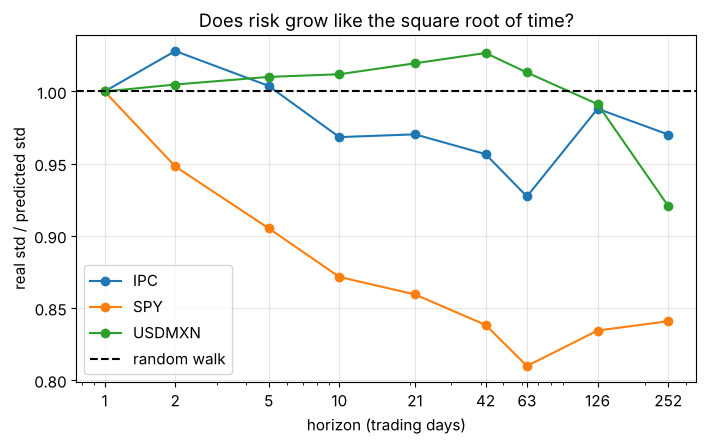

In [2]:
horizons = np.array([1, 2, 5, 10, 21, 42, 63, 126, 252])
print(f"{'days':>5}" + "".join(f"{c:>10}" for c in ["IPC", "SPY", "USDMXN"]) + "   (ratio = real std / (daily std x sqrt(days)))")
ratios = {}
for c in ["IPC", "SPY", "USDMXN"]:
    logp = np.log(prices[c].dropna()).values
    d = np.diff(logp).std()
    ratios[c] = [np.std(logp[h:] - logp[:-h]) / (d * sqrt(h)) for h in horizons]
for i, h in enumerate(horizons):
    print(f"{h:>5}" + "".join(f"{ratios[c][i]:>10.2f}" for c in ratios))

for c, v in ratios.items():
    plt.plot(horizons, v, "o-", label=c)
plt.axhline(1, color="black", ls="--", label="random walk")
plt.xscale("log"); plt.xticks(horizons, horizons)
plt.title("Does risk grow like the square root of time?")
plt.xlabel("horizon (trading days)"); plt.ylabel("real std / predicted std"); plt.legend(); plt.show()

For the IPC and the peso the rule works well, with ratios between 0.92 and 1.03 at every horizon. The
SPY is different, since its real risk over one month is only 0.86 of what the rule predicts, and over
one year 0.84. So if I take the daily volatility of the SPY and multiply it by $\sqrt{252}$, I get
around 19% more yearly risk than what really happened. In this sample the SPY partly reversed its moves
in the following days. Section 8 tests if this is strong enough to reject the random walk, and it is not,
so I read it as what happened in these 21 years and not as a rule. For the IPC and the peso, converting
a daily risk into a monthly or yearly one with $\sqrt{t}$ is a good approximation.

## 2. Stationarity: what does not change with time

A process is weakly stationary if its mean and its variance do not change with time, and the
covariance between two days depends only on the distance between them, not on the calendar. Most
models in the course need this property, so I want to check what is stationary in real data and what
is not.

**Exercise 2. Prices or returns?** I split the history of the IPC in four periods and I compare, for
each one, the mean and the standard deviation of the price, the mean and the volatility of the daily
returns, and the correlation of each return with the one of the day before.

period       mean price  std price  mean ret/yr   vol/yr  lag-1 corr
2005-2009        23,333      6,225       18.11%   25.81%       0.099
2010-2014        38,689      4,022        5.97%   15.13%       0.020
2015-2019        45,743      2,818        0.18%   13.63%       0.105
2020-2026        52,511      8,160        6.31%   17.21%      -0.013


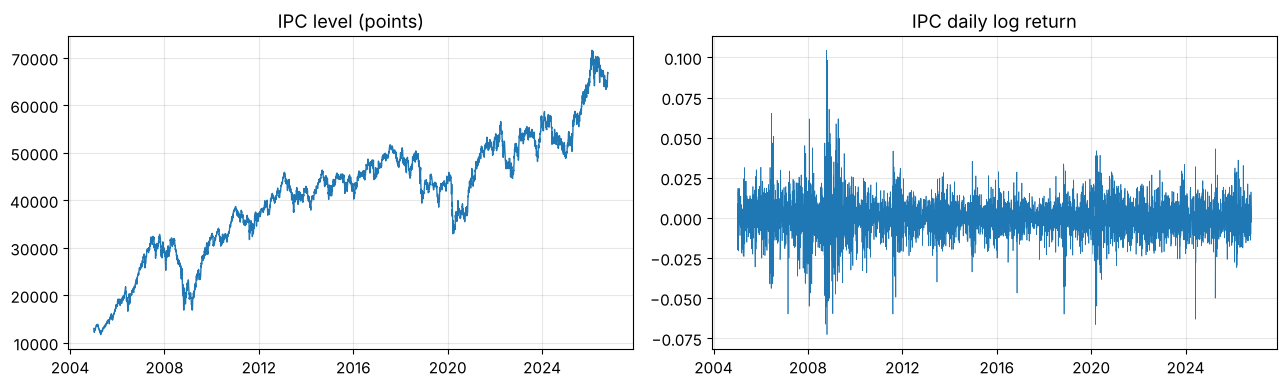

In [3]:
ipc = prices["IPC"].dropna()
r = log_ret("IPC")

print(f"{'period':<11}{'mean price':>12}{'std price':>11}{'mean ret/yr':>13}{'vol/yr':>9}{'lag-1 corr':>12}")
for a, b in [("2005", "2009"), ("2010", "2014"), ("2015", "2019"), ("2020", "2026")]:
    p, x = ipc[a:b], r[a:b]
    print(f"{a}-{b:<6}{p.mean():>12,.0f}{p.std():>11,.0f}{x.mean() * 252:>13.2%}{x.std() * sqrt(252):>9.2%}{acf(x, 1):>12.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ipc.index, ipc, lw=1); ax[0].set_title("IPC level (points)")
ax[1].plot(r.index, r, lw=0.5); ax[1].set_title("IPC daily log return")
plt.tight_layout(); plt.show()

The price is clearly not stationary. Its mean goes from 23,333 points in 2005–2009 to 52,511 in
2020–2026, so it depends completely on when I measure it. The returns are much closer to stationary,
but not completely. The correlation with the day before stays small in every period, between $-0.01$
and $0.11$, but the volatility goes from 25.8% in 2005–2009, which includes 2008, to 13.6% in
2015–2019. The mean return also moves a lot, from 18.1% to 0.2%, but Module 1 showed that five years
are too few to estimate a mean, so most of that change is noise. So the returns are stable in their
memory and only roughly stable in their size, and this is why every model in this notebook works with
returns and not with prices.

## 3. The random walk with drift: return grows like $t$, risk like $\sqrt{t}$

To model markets, each step becomes $r = \mu + \sigma z$: an expected return $\mu$ plus a volatility
$\sigma$ times a random shock. After $t$ years the mean is $\mu t$ and the standard deviation is
$\sigma\sqrt{t}$. Since the mean grows faster than the risk, the probability of losing money goes
down with time:

$$P(\text{loss after } t \text{ years}) = \Phi\!\left(-\frac{\mu\sqrt{t}}{\sigma}\right).$$

**Exercise 3. The probability of losing money.** For the IPC and the SPY in pesos I compute the mean
and the risk for 1, 3, 5 and 10 years, the probability of a loss that the formula gives, and the share
of real windows of that length that ended with a loss.

In [4]:
print(f"{'years':>5}{'mean':>9}{'std':>8}{'P(loss) normal':>16}{'P(loss) history':>17}{'windows':>9}")
for c in ["IPC", "SPY_MXN"]:
    x = log_ret(c)
    mu, sig = x.mean() * 252, x.std() * sqrt(252)
    logp = np.log(prices[c].dropna()).values
    print(c)
    for y in [1, 3, 5, 10]:
        h = 252 * y
        window = logp[h:] - logp[:-h]                     # every y-year return in the history (overlapping)
        p_norm = normal_cdf(-mu * y / (sig * sqrt(y)))    # P(sum of returns < 0) for a random walk with drift
        print(f"{y:>5}{mu * y:>9.1%}{sig * sqrt(y):>8.1%}{p_norm:>16.1%}{np.mean(window < 0):>17.1%}{len(logp) // h:>9}")

years     mean     std  P(loss) normal  P(loss) history  windows
IPC
    1     7.5%   18.5%           34.1%            31.3%       21
    3    22.6%   32.0%           24.0%            15.8%        7
    5    37.7%   41.3%           18.1%            10.0%        4
   10    75.4%   58.3%            9.8%             0.0%        2
SPY_MXN
    1    12.8%   18.4%           24.3%            15.1%       21
    3    38.4%   31.9%           11.4%             9.2%        7
    5    64.1%   41.2%            6.0%             0.0%        4
   10   128.1%   58.2%            1.4%             0.0%        2


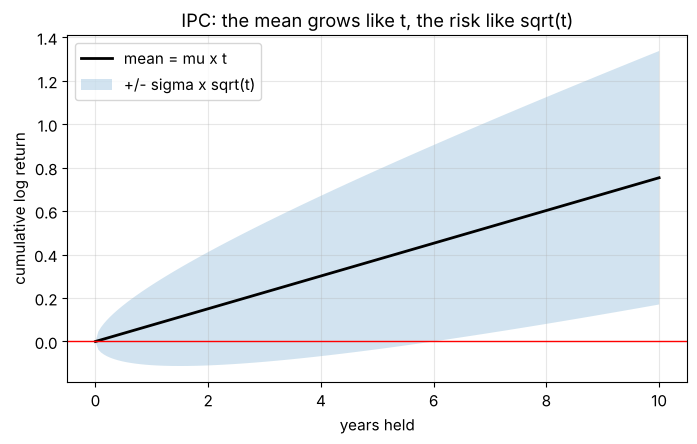

In [5]:
x = log_ret("IPC")
mu, sig = x.mean() * 252, x.std() * sqrt(252)
t = np.linspace(0, 10, 200)
plt.plot(t, mu * t, color="black", lw=2, label="mean = mu x t")
plt.fill_between(t, mu * t - sig * np.sqrt(t), mu * t + sig * np.sqrt(t), alpha=0.2, label="+/- sigma x sqrt(t)")
plt.axhline(0, color="red", lw=1)
plt.title("IPC: the mean grows like t, the risk like sqrt(t)")
plt.xlabel("years held"); plt.ylabel("cumulative log return"); plt.legend(); plt.show()

The formula and the history tell the same story: the longer the investment, the lower the chance of
losing money. For the IPC the formula goes from 34.1% at one year to 9.8% at ten years, and for the SPY
in pesos from 24.3% to 1.4%. The history gives even lower numbers, and no ten-year window lost money in
either series. I have to be careful with that last result, because 21 years of data have only two
ten-year periods that do not overlap, so "0% of the windows" is really based on two observations. The
formula also depends on $\mu$, which Module 1 showed is very hard to estimate, so these probabilities
are a guide and not a promise.

## 4. From normal returns to lognormal prices (Monte Carlo)

If log returns are normal, prices are **lognormal**. The distribution of the final price is skewed to
the right, and its mean is above its median because of the $\tfrac12\sigma^2$ term:

$$\mathbb{E}[P_T]=P_0\,e^{(\mu+\frac12\sigma^2)T}, \qquad \text{median}(P_T)=P_0\,e^{\mu T}.$$

**Exercise 4. Ten years in the IPC.** I simulate 20,000 possible paths of 100,000 pesos invested in the
IPC for 10 years, using the daily drift and volatility of its history, and I compare the mean and the
median of the final value with the formulas.

mean final value  :    253,972   (formula 251,918)
median final value:    215,036   (formula 212,489)
paths that end below the mean : 61.3%
paths that end below 100,000  : 9.5%


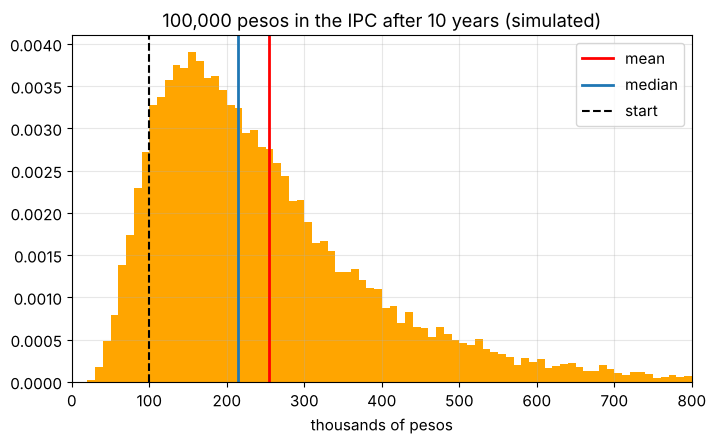

In [6]:
x = log_ret("IPC")
mu_d, sig_d = x.mean(), x.std()
years, n_paths, start = 10, 20_000, 100_000

# 20,000 possible futures of 100,000 pesos in the IPC, using the drift and volatility of the history
steps = np.random.normal(mu_d, sig_d, size=(n_paths, 252 * years))
final = start * np.exp(steps.sum(axis=1))

mean_theory = start * np.exp((mu_d + sig_d**2 / 2) * 252 * years)
median_theory = start * np.exp(mu_d * 252 * years)
print(f"mean final value  : {final.mean():>10,.0f}   (formula {mean_theory:,.0f})")
print(f"median final value: {np.median(final):>10,.0f}   (formula {median_theory:,.0f})")
print(f"paths that end below the mean : {np.mean(final < final.mean()):.1%}")
print(f"paths that end below 100,000  : {np.mean(final < start):.1%}")

plt.hist(final / 1000, bins=np.arange(0, 810, 10), density=True, color="orange")
plt.axvline(final.mean() / 1000, color="red", lw=2, label="mean")
plt.axvline(np.median(final) / 1000, lw=2, label="median")
plt.axvline(start / 1000, color="black", ls="--", label="start")
plt.xlim(0, 800); plt.title("100,000 pesos in the IPC after 10 years (simulated)")
plt.xlabel("thousands of pesos"); plt.legend(); plt.show()

The simulation matches the formulas: the mean final value is 253,972 pesos (formula 251,918) and the
median is 215,036 (formula 212,489). The difference between the two is the important part. The mean is
pulled up by a few very good paths, so 61.3% of the paths end below the mean. In practice, when someone
shows a projection with the "expected" value of an investment, most people will end with less than
that number, and the median is a better idea of what a typical investor gets. Also, 9.5% of the paths
end with less than the 100,000 pesos that went in.

## 5. Memory by construction: the MA model

The **moving-average** model $x_t = z_t + \theta\, z_{t-1}$ makes two neighboring values share one
shock, so they are correlated, while values two or more steps apart are not. More generally, an
MA($q$) has an autocorrelation that **cuts off** after lag $q$.

A very common real example is a return computed over overlapping windows. If I compute a 5-day return
every day, today's and yesterday's values share 4 of their 5 days, so they are correlated even if the
days are independent. The theory gives $\rho_k = (5-k)/5$ for $k \le 4$ and zero after that, which is
an MA(4).

**Exercise 5. Overlapping weekly returns.** I compute 5-day returns of the SPY every day and I measure
their autocorrelation at lags 1 to 10.

 lag     data  independent days  real daily autocorr
   1   +0.753             0.800               +0.753
   2   +0.540             0.600               +0.541
   3   +0.346             0.400               +0.346
   4   +0.136             0.200               +0.136
   5   -0.074             0.000               -0.074
   6   -0.033             0.000               -0.034
   7   -0.004             0.000               -0.004
   8   +0.006             0.000               +0.006
   9   +0.032             0.000               +0.032
  10   +0.030             0.000               +0.030


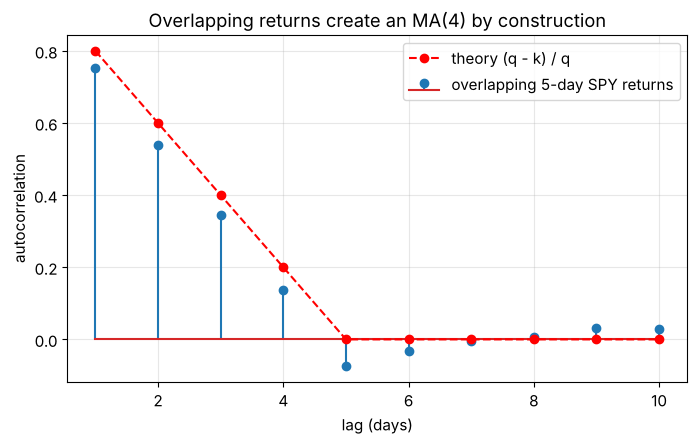

In [7]:
x = log_ret("SPY").values
q = 5
weekly = np.convolve(x, np.ones(q), "valid")      # 5-day return computed every day: windows overlap

lags = np.arange(1, 11)
emp = [acf(weekly, k) for k in lags]
theory = [max(q - k, 0) / q for k in lags]        # MA(4) of independent days: (q - k) / q

# the same theory without assuming independence: use the SPY's own daily autocorrelations
rho = np.r_[1, [acf(x, k) for k in range(1, 15)]]
def cov_sum(k):                                    # covariance of two q-day sums k days apart, in daily variances
    return sum(rho[abs(k + i - j)] for i in range(q) for j in range(q))
theory_real = [cov_sum(k) / cov_sum(0) for k in lags]

print(f"{'lag':>4}{'data':>9}{'independent days':>18}{'real daily autocorr':>21}")
for k, e, th, tr in zip(lags, emp, theory, theory_real):
    print(f"{k:>4}{e:>+9.3f}{th:>18.3f}{tr:>+21.3f}")

plt.stem(lags, emp, label="overlapping 5-day SPY returns")
plt.plot(lags, theory, "o--", color="red", label="theory (q - k) / q")
plt.title("Overlapping returns create an MA(4) by construction")
plt.xlabel("lag (days)"); plt.ylabel("autocorrelation"); plt.legend(); plt.show()

The autocorrelation follows the theory: it falls step by step until lag 4 and is close to zero from lag
5, which is the cut-off of an MA(4). The values are a bit below the theory, 0.75 against 0.80 at lag 1,
and the last column shows why. If the theory uses the real daily autocorrelations of the SPY instead of
assuming independent days, it gives 0.753 at lag 1, exactly the data, and it also matches the other
lags. So the gap comes from the small negative autocorrelation of the daily SPY returns, and the MA(4)
structure comes from the overlapping windows. This is a practical warning. Many
reports use rolling 12-month returns updated every month, and those series look very persistent even
if the market has no memory at all. I used overlapping windows myself in Section 3, and this is why I
said that the ten-year result was really based on two observations.

## 6. The AR model and mean reversion

The **autoregressive** model $v_t = c + \phi\, v_{t-1} + \sigma z_t$ uses the previous value, so its
memory fades slowly instead of cutting off. When $0<\phi<1$ the process is pulled back to its long-run
mean, and its moments are

$$\text{mean} = \frac{c}{1-\phi}, \qquad \text{variance} = \frac{\sigma^2}{1-\phi^2}, \qquad
\rho_k = \phi^k.$$

Module 1 showed that returns have almost no memory but their size does. So here I fit an AR(1) to the
**monthly volatility** of the IPC. I use the log of the volatility so the shocks are more symmetric, I
estimate $\phi$ with least squares written by hand, and I compute the half-life, the number of months
until half of a shock is gone, $\ln(0.5)/\ln(\phi)$.

**Exercise 6. Does volatility go back to its average?**

phi = 0.593   long-run volatility = 15.0%   half-life = 1.3 months
variance: data 0.1640   theory sigma^2 / (1 - phi^2) = 0.1642
highest months: Oct 2008 74%, Mar 2020 52%

rho_1 = 0.593   phi^1 = 0.593
rho_2 = 0.410   phi^2 = 0.352
rho_3 = 0.369   phi^3 = 0.209
rho_4 = 0.258   phi^4 = 0.124
rho_5 = 0.238   phi^5 = 0.073
rho_6 = 0.202   phi^6 = 0.044


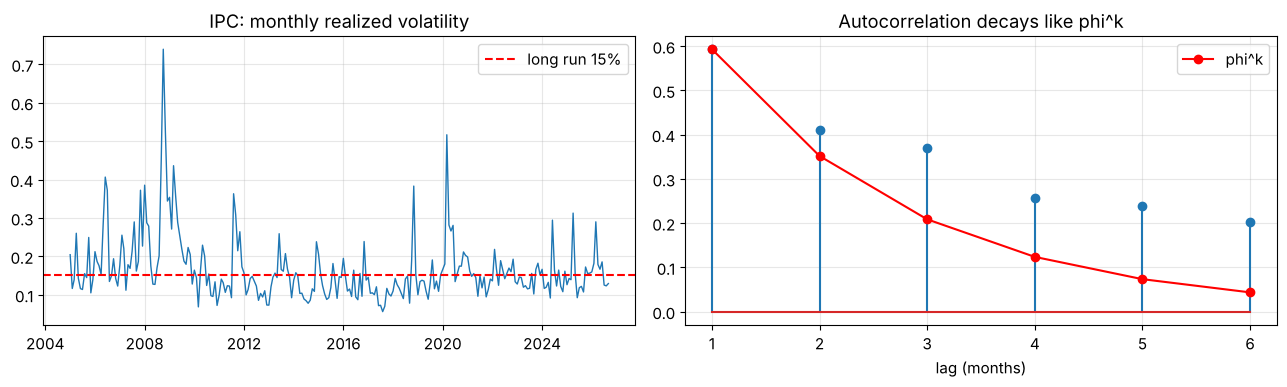

In [8]:
# monthly realized volatility of the IPC: std of the daily returns inside each month, annualized
x = log_ret("IPC")
vol = x.groupby(x.index.to_period("M")).std() * sqrt(252)
vol = vol[x.groupby(x.index.to_period("M")).size() >= 15]   # skip months with few days
v = np.log(vol.values)                                       # log, so the shocks are closer to normal

# fit v_t = c + phi * v_(t-1) + e_t by least squares, written by hand
y, z = v[1:], v[:-1]
phi = np.sum((z - z.mean()) * (y - y.mean())) / np.sum((z - z.mean())**2)
c = y.mean() - phi * z.mean()
resid = y - c - phi * z
long_run = np.exp(c / (1 - phi))

print(f"phi = {phi:.3f}   long-run volatility = {long_run:.1%}   half-life = {np.log(0.5) / np.log(phi):.1f} months")
print(f"variance: data {v.var():.4f}   theory sigma^2 / (1 - phi^2) = {resid.var() / (1 - phi**2):.4f}")
print(f"highest months: Oct 2008 {vol[pd.Period('2008-10', 'M')]:.0%}, Mar 2020 {vol[pd.Period('2020-03', 'M')]:.0%}\n")
lags = np.arange(1, 7)
for k in lags:
    print(f"rho_{k} = {acf(v, k):.3f}   phi^{k} = {phi**k:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(vol.index.to_timestamp(), vol.values, lw=1)
ax[0].axhline(long_run, color="red", ls="--", label=f"long run {long_run:.0%}")
ax[0].set_title("IPC: monthly realized volatility"); ax[0].legend()
ax[1].stem(lags, [acf(v, k) for k in lags])
ax[1].plot(lags, phi**lags, "o-", color="red", label="phi^k")
ax[1].set_title("Autocorrelation decays like phi^k"); ax[1].set_xlabel("lag (months)"); ax[1].legend()
plt.tight_layout(); plt.show()

The volatility of the IPC clearly goes back to its average. The fitted $\phi$ is 0.593, the long-run
level is around 15%, and the variance formula matches the data (0.1642 against 0.1640). The plot on the
left shows the idea: in October 2008 and March 2020 the volatility jumped to 74% and 52%, and in both
cases it went back toward 15%. The plot on the right shows a limit of the model. The first lag matches
$\phi$ exactly, but that is how $\phi$ was fitted, so it is not a test. The next lags decay more slowly
than $\phi^k$, and at 6 months the data still has 0.20 when the AR(1) says 0.04. So the volatility has
a longer memory than one AR(1) can describe, and a half-life of 1.3 months is too optimistic about how
fast a crisis goes away.

## 7. AR(1) is an MA($\infty$) in disguise

If I substitute the AR(1) into itself again and again, the deviation from the long-run mean becomes a
weighted sum of all past shocks:

$$v_t - m = e_t + \phi\, e_{t-1} + \phi^2 e_{t-2} + \dots$$

So each shock keeps a weight $\phi^k$ after $k$ periods, and since $\phi^k \to 0$, a few dozen terms
are enough.

**Exercise 7. Rebuilding the volatility from its shocks.** With the shocks of the model from Section 6,
I rebuild the series as a weighted sum of the last 36 shocks and compare it with the data. I also print
how much of a shock is left after $k$ months.

largest gap after the first 36 months: 0.0000

how much of a shock is left after k months:
    1 months: 59%
    3 months: 21%
    6 months: 4%
   12 months: 0%
   24 months: 0%


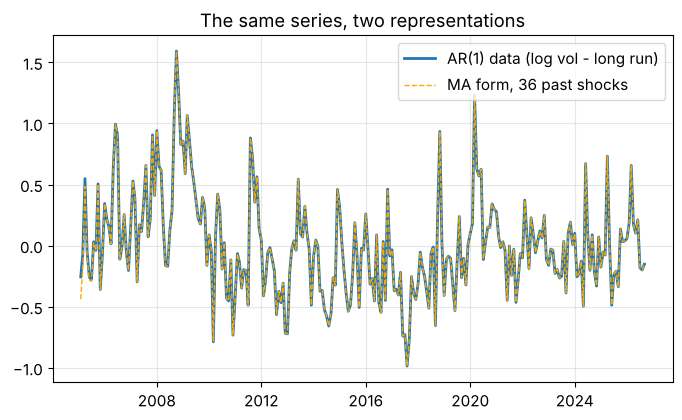

In [9]:
# rebuild the deviations from the long-run level using only past shocks: sum of phi^k * e_(t-k)
m = c / (1 - phi)
dev = v[1:] - m
K = 36
rebuilt = np.array([sum(phi**k * resid[t - k] for k in range(min(t, K) + 1)) for t in range(len(resid))])
print(f"largest gap after the first {K} months: {np.max(np.abs(dev[K:] - rebuilt[K:])):.4f}\n")

print("how much of a shock is left after k months:")
for k in [1, 3, 6, 12, 24]:
    print(f"   {k:>2} months: {phi**k:.0%}")

idx = vol.index[1:].to_timestamp()
plt.plot(idx, dev, lw=2, label="AR(1) data (log vol - long run)")
plt.plot(idx, rebuilt, color="orange", ls="--", lw=1, label=f"MA form, {K} past shocks")
plt.title("The same series, two representations"); plt.legend(); plt.show()

The two lines are the same, with a largest gap below 0.0001 after the first 36 months. So the AR(1) can
be read in two ways: today's volatility depends on last month's volatility, or today's volatility is
the sum of all past shocks, each one smaller the older it is. The second reading is useful in practice
because it says how long a shock lasts. With $\phi = 0.593$, 59% of a shock is left after one month,
21% after three and almost nothing after a year. Section 6 showed that the real memory is longer, so I
read these numbers as the fast part of the decay and not the whole story.

## 8. Testing the random walk: the variance ratio

If prices follow a random walk, the variance of $q$-day returns is exactly $q$ times the variance of
one-day returns. The **variance ratio**

$$VR(q) = \frac{\mathrm{Var}(r^{(q)})}{q\cdot \mathrm{Var}(r^{(1)})}$$

should then be around 1. Values below 1 mean that moves partly reverse (mean reversion), and values
above 1 mean that moves continue (momentum). Under a random walk, the standard error is about
$\sqrt{2(2q-1)(q-1)/(3qT)}$, so values more than two standard errors away from 1 are unlikely to be
noise.

That formula assumes that the volatility never changes, and Module 1 showed that it does: there are
calm periods and crisis periods. When the volatility changes, a few crisis days carry a lot of weight,
so there is less information in the data than the number of days suggests, and the band should be
wider. Lo and MacKinlay, who proposed the test, also gave a robust standard error for this case, and I
compute both.

**Exercise 8. Variance ratio for five real series.** I compute $VR(q)$ for 2, 5, 10 and 21 days, and
for the SPY I repeat the test in three periods.

series       VR(2)    VR(5)   VR(10)   VR(21)   band, constant vol  band, robust  z robust
IPC           1.06     1.01     0.94     0.94              +/-0.14       +/-0.23      -0.5
SPY           0.90     0.82     0.76     0.74              +/-0.14       +/-0.33      -1.6
USDMXN        1.01     1.02     1.02     1.04              +/-0.14       +/-0.26      +0.3
TLT           0.97     0.87     0.82     0.85              +/-0.14       +/-0.21      -1.4
GLD           0.98     0.96     0.93     0.89              +/-0.14       +/-0.19      -1.1
SPY 2005-2012: VR(21) = 0.68
SPY 2013-2019: VR(21) = 0.72
SPY 2020-2026: VR(21) = 0.82


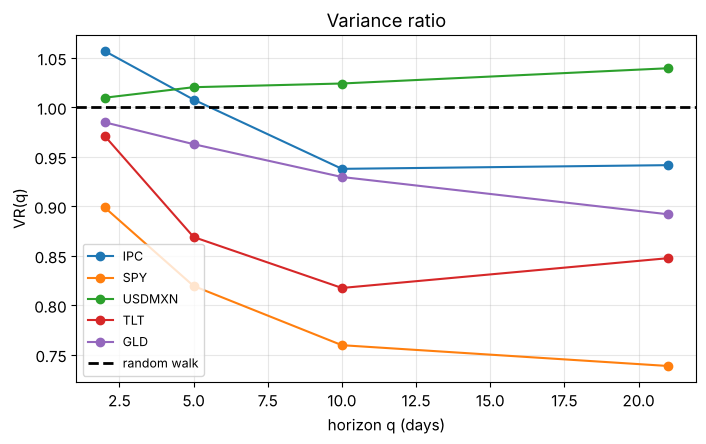

In [10]:
qs = [2, 5, 10, 21]
def vr_robust_se(r1, q):
    # Lo-MacKinlay (1988) standard error that allows the volatility to change over time
    e2 = (r1 - r1.mean())**2
    T, den = len(r1), np.sum(e2)**2
    theta = sum((2 * (q - j) / q)**2 * T * np.sum(e2[j:] * e2[:-j]) / den for j in range(1, q))
    return sqrt(theta / T)

print(f"{'series':<9}" + "".join(f"{'VR(' + str(q) + ')':>9}" for q in qs)
      + f"{'band, constant vol':>21}{'band, robust':>14}{'z robust':>10}")
vr_all = {}
for c in ["IPC", "SPY", "USDMXN", "TLT", "GLD"]:
    logp = np.log(prices[c].dropna()).values
    r1 = np.diff(logp)
    T = len(r1)
    vr = [np.var(logp[q:] - logp[:-q], ddof=1) / (q * np.var(r1, ddof=1)) for q in qs]
    se21 = sqrt(2 * (2 * 21 - 1) * (21 - 1) / (3 * 21 * T))     # assumes the volatility never changes
    se21_r = vr_robust_se(r1, 21)
    vr_all[c] = vr
    print(f"{c:<9}" + "".join(f"{v:>9.2f}" for v in vr)
          + f"{'+/-' + format(2 * se21, '.2f'):>21}{'+/-' + format(2 * se21_r, '.2f'):>14}{(vr[-1] - 1) / se21_r:>+10.1f}")

# is the SPY result only a crisis effect? same test by period
spy = np.log(prices["SPY"].dropna())
for a, b in [("2005", "2012"), ("2013", "2019"), ("2020", "2026")]:
    lp = spy[a:b].values
    r1 = np.diff(lp)
    print(f"SPY {a}-{b}: VR(21) = {np.var(lp[21:] - lp[:-21], ddof=1) / (21 * np.var(r1, ddof=1)):.2f}")

for c, vr in vr_all.items():
    plt.plot(qs, vr, "o-", label=c)
plt.axhline(1, color="black", ls="--", lw=2, label="random walk")
plt.title("Variance ratio"); plt.xlabel("horizon q (days)"); plt.ylabel("VR(q)")
plt.legend(fontsize=9); plt.show()

With the simple band of $\pm 0.14$, the SPY (0.74) and long US bonds (TLT, 0.85) look clearly below 1,
and in a first version of this notebook I wrote that the SPY was a clear exception to the random walk.
The robust band changes that conclusion. It is between $\pm 0.19$ and $\pm 0.33$, almost twice as wide,
and no series is more than two robust standard errors away from 1. The SPY has the lowest ratio, with a
robust z of $-1.6$, and it is below 1 in the three periods (0.68, 0.72 and 0.82), so there is a hint of
partial reversal, but it is not strong enough to reject the random walk. The IPC (0.94), the peso
(1.04) and gold (0.89) are closer to 1. So the random walk survives this test for the five series, and
the lesson is about the test itself: a standard error that ignores changing volatility makes a result
look much stronger than it is.

## Wrapping up Module 2

This module added time to the random variables of Module 1. The simple rules work better than I
expected: risk grows like $\sqrt{t}$ for the IPC and the peso, the chance of losing money falls with
the horizon, and the mean of a lognormal price sits above what a typical investor gets. The exceptions
are smaller than they first looked. In these 21 years the SPY partly reversed its moves, so $\sqrt{t}$
overstated its risk, but once the changing volatility is taken into account the variance ratio cannot
say that this is more than noise. The volatility of the IPC goes back to its average, but more slowly
than a simple AR(1) says.

Three lessons came from the data itself and not from the course. Overlapping returns create memory that
is not real, the timing of a data source can create patterns that are not real either, and a standard
error that ignores changing volatility makes a weak result look strong. In all three cases the only way
to notice was to check the numbers before using them.

The next step is Module 3, where the question changes from describing these processes to estimating
them from data and using them to forecast.